# Matched-filter peak detection demo

This notebook simulates a small set of TESS-like candidate light curves, builds a coarse bank of self-lensing templates, and searches each candidate with `selflensing.matched_filtering.detect_matched_filter_peaks`. The candidate systems cover the same broad parameter range as the template bank, but deliberately do not use the exact template parameters.

In [1]:
from astropy import units
from astropy.time import Time
from astropy.visualization import quantity_support

from matplotlib import pyplot

import numpy

from selflensing.generators import LightcurveGenerator
from selflensing.matched_filtering import (
    MatchedFilterTemplate,
    detect_matched_filter_peaks,
)
from selflensing.models import SelfLensingSystem

In [2]:
quantity_support()

<astropy.visualization.units.quantity_support.<locals>.MplQuantityConverter at 0x122a30050>

## Simulate candidate light curves to search

In real use, `time` and `flux` would come from observed light curves. Here we generate a few synthetic candidates with light noise so the expected event times are known. Their parameters sit between the template-bank grid points rather than matching them exactly.

In [3]:
start_time = Time("2025-01-01")
end_time = Time("2025-01-27")
tess_bins = 27 * 24 * 6

tess_cadence = ((end_time.jd - start_time.jd) / (tess_bins - 1)) * units.day
template_cadence = tess_cadence * 4

candidate_specs = [
    {"a": 6.0, "Macc": 4.7, "Mcomp": 0.95, "peak_time": Time("2025-01-09")},
    {"a": 35.0, "Macc": 8.0, "Mcomp": 1.05, "peak_time": Time("2025-01-14")},
    {"a": 80.0, "Macc": 9.2, "Mcomp": 1.08, "peak_time": Time("2025-01-20")},
]

rng = numpy.random.default_rng(42)

candidate_lightcurves = []
for spec in candidate_specs:
    system = SelfLensingSystem(
        a=spec["a"] * units.AU,
        i=(0.5 * numpy.pi) * units.rad,
        Macc=spec["Macc"] * units.M_sun,
        Mcomp=spec["Mcomp"] * units.M_sun,
        e=0 * units.dimensionless_unscaled,
        d=1 * units.kpc,
    )
    lcg = LightcurveGenerator(
        system,
        start_time=start_time,
        end_time=end_time,
        peak_time=spec["peak_time"],
        ev=True,
        db=True,
        sl=True,
        bins=tess_bins,
    )
    flux = numpy.asarray(lcg.flux_array, dtype=float)
    flux = flux / numpy.nanmedian(flux)
    flux = flux + rng.normal(0.0, 0.001, size=len(flux))
    label = (
        f"a={spec['a']} AU, Macc={spec['Macc']} Msun, "
        f"Mcomp={spec['Mcomp']} Msun"
    )
    candidate_lightcurves.append(
        {
            "label": label,
            "times": lcg.times,
            "flux": flux,
            "peak_time": spec["peak_time"],
        }
    )

[(candidate["label"], candidate["peak_time"].iso) for candidate in candidate_lightcurves]

[('a=6.0 AU, Macc=4.7 Msun, Mcomp=0.95 Msun', '2025-01-09 00:00:00.000'),
 ('a=35.0 AU, Macc=8.0 Msun, Mcomp=1.05 Msun', '2025-01-14 00:00:00.000'),
 ('a=80.0 AU, Macc=9.2 Msun, Mcomp=1.08 Msun', '2025-01-20 00:00:00.000')]

Text(0.5, 0, 'Time [JD]')

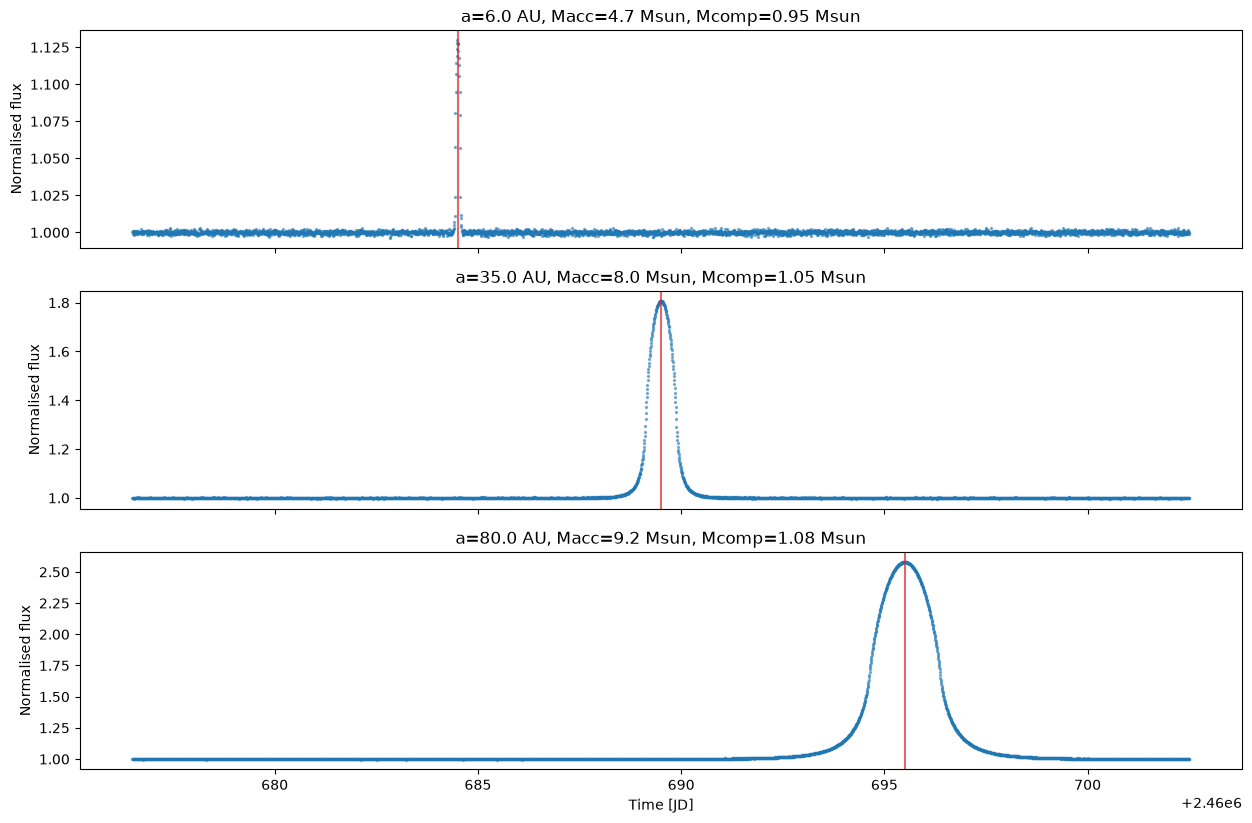

In [4]:
fig, axes = pyplot.subplots(
    len(candidate_lightcurves),
    1,
    figsize=(15, 3.2 * len(candidate_lightcurves)),
    sharex=True,
)
if len(candidate_lightcurves) == 1:
    axes = [axes]

for ax, candidate in zip(axes, candidate_lightcurves):
    ax.scatter(candidate["times"].jd, candidate["flux"], s=2, alpha=0.5, c="tab:blue")
    ax.axvline(candidate["peak_time"].jd, color="tab:red", alpha=0.7)
    ax.set_ylabel("Normalised flux")
    ax.set_title(candidate["label"])

axes[-1].set_xlabel("Time [JD]")

## Build a small template bank

Templates carry their own time grid. The matched-filter module resamples each template to the median cadence of the target light curve before filtering, so the bank can be generated at a different cadence. Later this can be replaced with a larger precomputed template library.

In [5]:
def template_times_for_system(system, cadence, template_peak_time):
    half_bins = int(
        numpy.ceil(system.tau_eff.to_value(units.day) / cadence.to_value(units.day))
    )
    offsets = numpy.arange(-half_bins, half_bins + 1) * cadence
    return template_peak_time + offsets


def make_template(system, cadence):
    template_peak_time = Time("2025-01-01")
    template_times = template_times_for_system(system, cadence, template_peak_time)
    template_lcg = LightcurveGenerator(
        system,
        times=template_times,
        peak_time=template_peak_time,
        ev=True,
        db=True,
        sl=True,
    )
    return MatchedFilterTemplate(
        flux=numpy.asarray(template_lcg.flux_array, dtype=float),
        time=template_lcg.times,
    )

In [6]:
template_specs = [
    {"a": 4.5, "Macc": 4.0, "Mcomp": 0.9},
    {"a": 20, "Macc": 10.0, "Mcomp": 1.0},
    {"a": 100, "Macc": 6.0, "Mcomp": 1.1},
]

templates = []
template_labels = []
for spec in template_specs:
    system = SelfLensingSystem(
        a=spec["a"] * units.AU,
        i=(0.5 * numpy.pi) * units.rad,
        Macc=spec["Macc"] * units.M_sun,
        Mcomp=spec["Mcomp"] * units.M_sun,
        e=0 * units.dimensionless_unscaled,
        d=1 * units.kpc,
    )
    template_labels.append(
        f"a={spec['a']} AU, Macc={spec['Macc']} Msun, Mcomp={spec['Mcomp']} Msun"
    )
    templates.append(make_template(system, template_cadence))

list(zip(template_labels, [len(template.flux) for template in templates]))

[('a=4.5 AU, Macc=4.0 Msun, Mcomp=0.9 Msun', 45),
 ('a=20 AU, Macc=10.0 Msun, Mcomp=1.0 Msun', 89),
 ('a=100 AU, Macc=6.0 Msun, Mcomp=1.1 Msun', 325)]

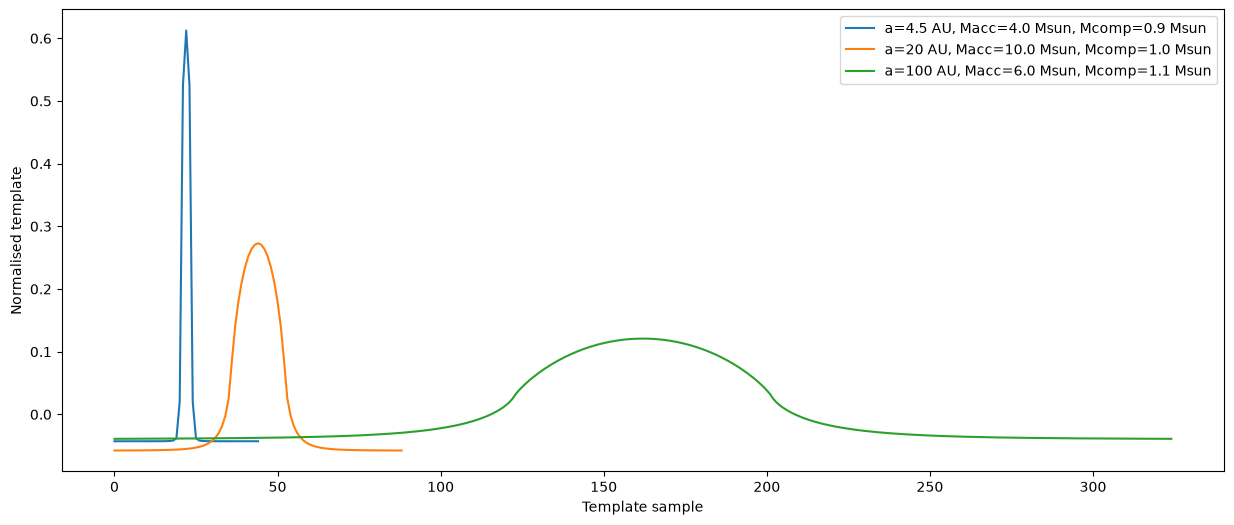

In [7]:
pyplot.figure(figsize=(15, 6))
for template, label in zip(templates, template_labels):
    template_flux = template.flux - numpy.mean(template.flux)
    template_flux = template_flux / numpy.sqrt(numpy.sum(template_flux**2))
    pyplot.plot(template_flux, label=label)
pyplot.xlabel("Template sample")
pyplot.ylabel("Normalised template")
pyplot.legend()

## Run the matched-filter search

`detect_matched_filter_peaks` handles the mean subtraction, template normalisation, valid cross-correlation, and `scipy.signal.find_peaks` call. The returned windows are mapped back onto the input light-curve timestamps.

In [8]:
candidate_results = []
for candidate_index, candidate in enumerate(candidate_lightcurves):
    matches = detect_matched_filter_peaks(
        candidate["times"],
        candidate["flux"],
        templates,
        max_matches=3,
    )
    candidate_results.append(matches)

    print(f"candidate={candidate_index} ({candidate['label']}), expected_peak={candidate['peak_time'].jd:.5f}")
    if not matches:
        print("  no matches")
    for match in matches:
        print(
            f"  template={match.template_index} ({template_labels[match.template_index]}): "
            f"start={match.start_time:.5f}, "
            f"peak={match.peak_time:.5f}, "
            f"end={match.end_time:.5f}, "
            f"score={match.score:.5g}, "
            f"prominence={match.prominence:.5g}"
        )

candidate=0 (a=6.0 AU, Macc=4.7 Msun, Mcomp=0.95 Msun), expected_peak=2460684.50000
  template=0 (a=4.5 AU, Macc=4.0 Msun, Mcomp=0.9 Msun): start=2460683.91137, peak=2460684.50000, end=2460685.08863, score=0.42312, prominence=0.47221
candidate=1 (a=35.0 AU, Macc=8.0 Msun, Mcomp=1.05 Msun), expected_peak=2460689.50000
  template=2 (a=100 AU, Macc=6.0 Msun, Mcomp=1.1 Msun): start=2460685.16890, peak=2460689.50334, end=2460693.83779, score=5.0383, prominence=6.7043
candidate=2 (a=80.0 AU, Macc=9.2 Msun, Mcomp=1.08 Msun), expected_peak=2460695.50000
  template=2 (a=100 AU, Macc=6.0 Msun, Mcomp=1.1 Msun): start=2460691.16221, peak=2460695.49666, end=2460699.83110, score=18.337, prominence=24.701


Text(0.5, 0, 'Time [JD]')

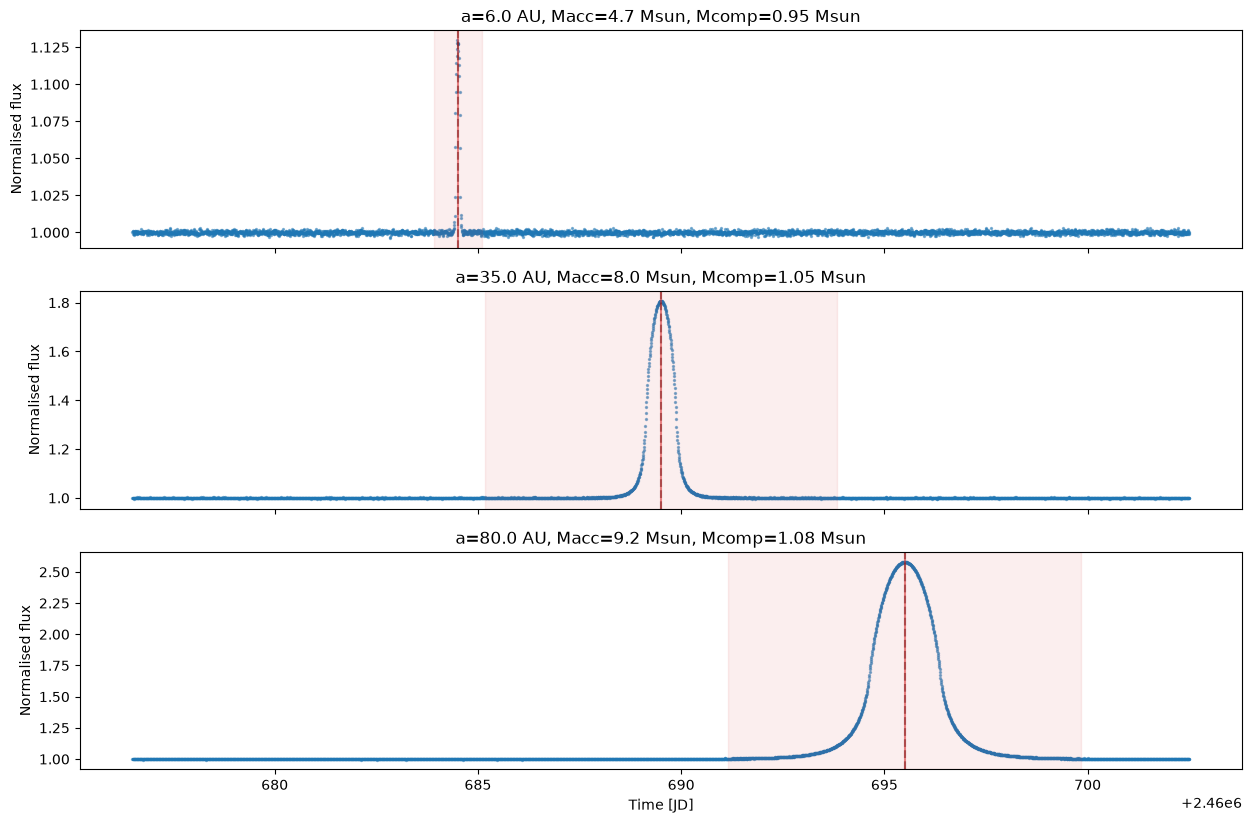

In [9]:
fig, axes = pyplot.subplots(
    len(candidate_lightcurves),
    1,
    figsize=(15, 3.2 * len(candidate_lightcurves)),
    sharex=True,
)
if len(candidate_lightcurves) == 1:
    axes = [axes]

for ax, candidate, matches in zip(axes, candidate_lightcurves, candidate_results):
    ax.scatter(candidate["times"].jd, candidate["flux"], s=2, alpha=0.5, c="tab:blue")
    ax.axvline(candidate["peak_time"].jd, color="black", linestyle="--", alpha=0.5)

    for match in matches:
        ax.axvspan(match.start_time, match.end_time, color="tab:red", alpha=0.08)
        ax.axvline(match.peak_time, color="tab:red", alpha=0.55)

    ax.set_ylabel("Normalised flux")
    ax.set_title(candidate["label"])

axes[-1].set_xlabel("Time [JD]")